# Ablação — de onde vem o desempenho?

Retirar grupos de atributos para examinar dependências. Esta é uma análise diagnóstica no dataset original já observado. Não promove uma variante para produção e não fornece um novo teste independente de melhoria.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml").is_dir() and (p / "sql").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from ml.data import load_tables
from ml.plotting import configure_style, style_table, save_figure
from ml.config import REPORTS, ARTIFACTS
get_ipython().run_line_magic("matplotlib", "inline")
configure_style()
pd.set_option("display.max_columns", 40)

import json
DESTINATION = ROOT / "ml/reports/robustness/rodada_01"
assert (DESTINATION / "protocolo_registrado.json").exists(), "Execute primeiro python -m ml.robustness.run"


## Grupos comparados

- Completo.
- Sem histórico: valor absoluto, calendário e categorias.
- **Desvios atuais + histórico** (`so_historico`): inclui o valor atual relativo ao passado; não significa observar apenas o passado.
- Sem categorias.
- Sem calendário.
- **Sem valor atual e derivados:** remove log do valor e todos os desvios/z que também carregam informação da transação atual.

Cada variante dos modelos aprendidos é ajustada só em 2024 e calibrada só no primeiro semestre/2025. Hiperparâmetros são os mesmos dos modelos originais; os pesos são reestimados em arquivos separados. As referências de regra comparam valor global, histórico completo e janela de 90 dias.

In [2]:
from ml.robustness.ablations import FEATURE_GROUPS, GROUP_LABELS
groups = pd.DataFrame([{"Grupo": GROUP_LABELS[name], "Numéricos": ", ".join(numeric), "Categóricos": ", ".join(categorical)} for name, (numeric, categorical) in FEATURE_GROUPS.items()])
display(style_table(groups))


Grupo,Numéricos,Categóricos
Completo,"log_valor, desvio_log_historico, z_historico, log_qtd_historico, desvio_log_90d, z_90d, log_qtd_90d, log_dias_desde_ultima, sem_historico, mes_sin, mes_cos, dia_semana_sin, dia_semana_cos","tipo_transacao, id_area_natural, id_categoria_natural"
Sem histórico,"log_valor, mes_sin, mes_cos, dia_semana_sin, dia_semana_cos","tipo_transacao, id_area_natural, id_categoria_natural"
Desvios atuais + histórico,"desvio_log_historico, z_historico, log_qtd_historico, desvio_log_90d, z_90d, log_qtd_90d, log_dias_desde_ultima, sem_historico",
Sem categorias,"log_valor, desvio_log_historico, z_historico, log_qtd_historico, desvio_log_90d, z_90d, log_qtd_90d, log_dias_desde_ultima, sem_historico, mes_sin, mes_cos, dia_semana_sin, dia_semana_cos",
Sem calendário,"log_valor, desvio_log_historico, z_historico, log_qtd_historico, desvio_log_90d, z_90d, log_qtd_90d, log_dias_desde_ultima, sem_historico","tipo_transacao, id_area_natural, id_categoria_natural"
Sem valor atual e derivados,"log_qtd_historico, log_qtd_90d, log_dias_desde_ultima, sem_historico, mes_sin, mes_cos, dia_semana_sin, dia_semana_cos","tipo_transacao, id_area_natural, id_categoria_natural"


In [3]:
ablations = pd.read_csv(DESTINATION / "ablacoes.csv")
display(style_table(ablations[["grupo", "modelo", "ap_validacao", "average_precision", "precision", "recall", "f1", "taxa_alerta"]].round(4)))


grupo,modelo,ap_validacao,average_precision,precision,recall,f1,taxa_alerta
completo,Isolation Forest,0.795600,0.829600,0.891800,0.765600,0.823900,0.056200
completo,Autoencoder,0.294400,0.351500,0.408400,0.364800,0.385300,0.058400
sem_historico,Isolation Forest,0.091800,0.101400,0.116100,0.249700,0.158500,0.140700
sem_historico,Autoencoder,0.081100,0.073000,0.069200,0.664400,0.125300,0.628100
so_historico,Isolation Forest,0.879500,0.924000,0.913400,0.965300,0.938600,0.069100
so_historico,Autoencoder,0.584000,0.502700,0.351100,0.549200,0.428300,0.102300
sem_categorias,Isolation Forest,0.888500,0.913500,0.938200,0.905700,0.921700,0.063100
sem_categorias,Autoencoder,0.386400,0.437000,0.549400,0.331500,0.413500,0.039500
sem_calendario,Isolation Forest,0.673100,0.755000,0.802000,0.764200,0.782700,0.062300
sem_calendario,Autoencoder,0.244700,0.243800,0.187600,0.309300,0.233500,0.107900


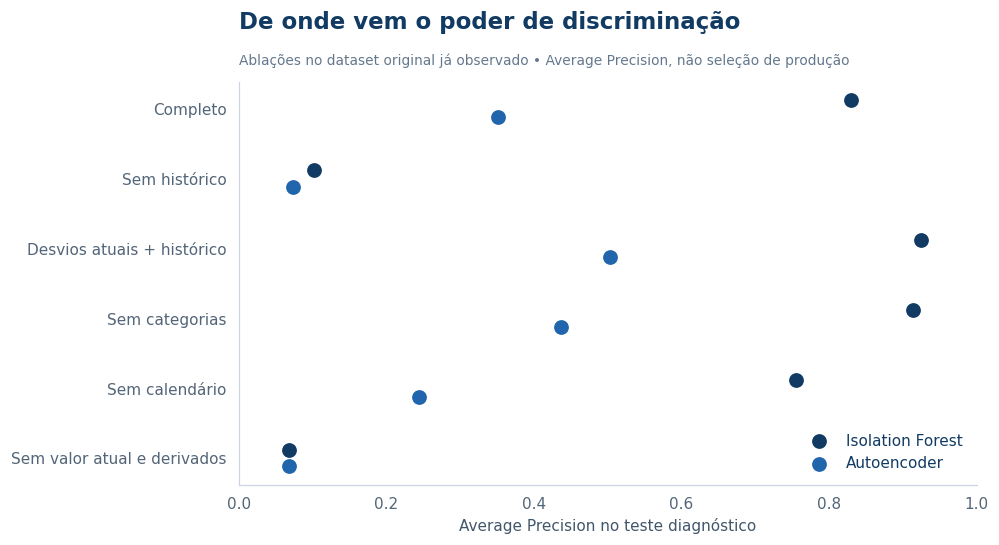

In [4]:
from ml.robustness.report import make_figures
figures = make_figures(DESTINATION)
display(figures[2])
for figure in figures:
    plt.close(figure)


## Interpretação

O contraste com o histórico do parceiro concentra grande parte do sinal nesta simulação. A AP próxima da prevalência no controle sem valor atual/derivados é esperada. Recall de 100% com alertas em praticamente todas as linhas é uma solução trivial, não uma melhoria.

Variantes mais simples podem melhorar modelos aprendidos no dataset observado. Essas descobertas são hipóteses para uma rodada futura com outro conjunto reservado, sem reutilizar o teste para confirmar a melhoria.